**CS 4140 – Deep Learning · L02 · From familiar ML to a first neural network** &nbsp; [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Bolufe-Rohler/4140-deep-learning/blob/main/lectures/L02_first-neural-network/L02_learning_in_two_spaces.ipynb)

Run the first code cell before anything else. In Colab, *File → Save a copy in Drive* keeps your own changes.

In [ ]:
# ▶ Run this cell first. It gets the course code and this lecture's saved results and data,
#   in Google Colab or on your own computer.
LECTURE = "L02_first-neural-network"
REPO = "https://github.com/Bolufe-Rohler/4140-deep-learning"
import os, sys, subprocess
root = os.path.abspath(os.path.join("..", ".."))
if not os.path.isfile(os.path.join(root, "cs4140_setup.py")):  # not inside the course repo (e.g. Colab)
    root = "/content/cs4140" if "google.colab" in sys.modules else os.path.abspath("cs4140")
    if not os.path.isdir(root):
        subprocess.run(["git", "clone", "--quiet", "--depth", "1", REPO, root], check=True)
    os.chdir(os.path.join(root, "lectures", LECTURE))
sys.path.insert(0, root)
import cs4140_setup
cs4140_setup.fetch_assets(LECTURE)

# CS 4140 · Lecture 2 — Demo: learning happens in weight space

**What to look for**

1. A hypothesis $h_\theta(x)=\theta_0+\theta_1x$ is a whole **function** (a line). It lives in the **hypothesis space**.
2. The weights $\theta=(\theta_0,\theta_1)$ are a single **point**. They live in the **weight space**, where the cost $J(\theta)$ is defined.
3. Gradient descent moves the point in weight space; we watch the line move in hypothesis space.
4. The same PyTorch recipe (model, loss, optimizer) trains logistic regression, which is a single neuron.

Runs on a laptop CPU in a few seconds. Set `SAVE_FIGS = True` to export the figures used in the slides.

In [1]:
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(0)
SAVE_FIGS = False
FIG_DIR = 'figures'
if SAVE_FIGS:
    import os
    os.makedirs(FIG_DIR, exist_ok=True)
plt.rcParams.update({'font.size': 14, 'mathtext.fontset': 'cm'})

## 1. Data: the ten houses from the slides
Size in m² and selling price in thousands of dollars. We measure size in **hundreds** of m² so both
weights end up on similar scales (a light form of the feature scaling you saw in Machine Learning).

x shape: (10, 1)  y shape: (10, 1)  m = 10


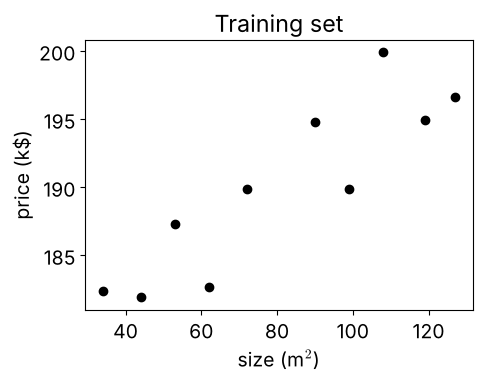

In [2]:
size_m2 = torch.tensor([34., 44., 53., 62., 72., 90., 99., 108., 119., 127.])
price_k = torch.tensor([182.4, 181.9, 187.3, 182.7, 189.9, 194.8, 189.9, 199.9, 194.9, 196.6])

x = (size_m2 / 100).unsqueeze(1)   # shape (m, 1): one feature per example
y = price_k.unsqueeze(1)           # shape (m, 1)
m = x.shape[0]
print('x shape:', tuple(x.shape), ' y shape:', tuple(y.shape), ' m =', m)

plt.figure(figsize=(5, 3.5))
plt.scatter(size_m2, price_k, color='k')
plt.xlabel('size (m$^2$)'); plt.ylabel('price (k\\$)'); plt.title('Training set')
plt.show()

## 2. The recipe in PyTorch
* **Hypothesis family** — `nn.Linear(1, 1)` computes $h_\theta(x)=\theta_0+\theta_1x$ with `bias` $=\theta_0$ and `weight` $=\theta_1$.
* **Cost** — `nn.MSELoss()` computes $\frac{1}{m}\sum_i (h_\theta(x^{(i)})-y^{(i)})^2$. The slides use $\frac{1}{2m}$; the factor $\frac12$ only rescales $J$ (and therefore the useful learning rate).
* **Optimizer** — `torch.optim.SGD` with the full training set at every step is exactly gradient descent: $\theta := \theta-\alpha\,\nabla_\theta J(\theta)$.

In [3]:
model = nn.Linear(1, 1)
with torch.no_grad():               # start from a deliberately bad line (negative slope), as in the slides
    model.bias.fill_(220.0)
    model.weight.fill_(-40.0)

loss_fn = nn.MSELoss()
opt = torch.optim.SGD(model.parameters(), lr=0.5)

path, losses = [], []
for step in range(300):
    y_hat = model(x)                # forward pass:   h_theta(x) for every training example
    loss = loss_fn(y_hat, y)        # cost:           J(theta)
    path.append((model.bias.item(), model.weight.item()))
    losses.append(loss.item())
    opt.zero_grad()                 # clear old gradients
    loss.backward()                 # gradient:       dJ/dtheta (autograd)
    opt.step()                      # update:         theta := theta - alpha * dJ/dtheta

path = np.array(path)
print(f'start  theta0 = {path[0,0]:7.2f}   theta1 = {path[0,1]:7.2f}   J = {losses[0]:9.2f}')
print(f'final  theta0 = {model.bias.item():7.2f}   theta1 = {model.weight.item():7.2f}   J = {losses[-1]:9.2f}')

start  theta0 =  220.00   theta1 =  -40.00   J =    328.40
final  theta0 =  175.82   theta1 =   17.59   J =      7.87


## 3. Watch both spaces at once
Left: hypothesis space (lines over the data). Middle: weight space (contours of $J$ and the path of gradient descent).
Right: the cost after each iteration. Every dot in the middle panel *is* one of the lines on the left.

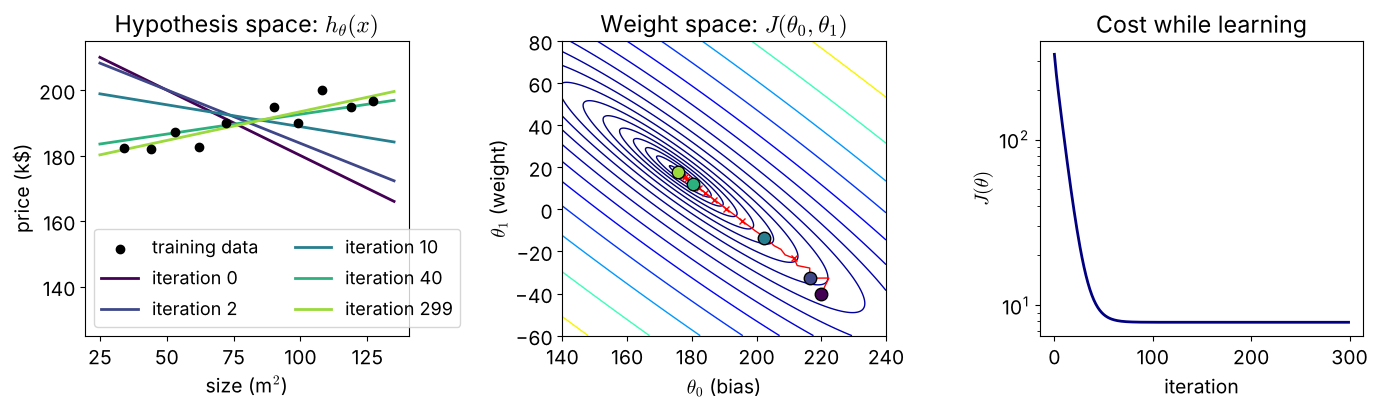

Predicted price of an 82 m^2 house: 190.2 k$


In [4]:
def J_grid(t0, t1):
    """MSE cost for every (theta0, theta1) on a grid (numpy)."""
    X = x.numpy().ravel(); Y = y.numpy().ravel()
    H = t0[..., None] + t1[..., None] * X
    return ((H - Y) ** 2).mean(axis=-1)

T0, T1 = np.meshgrid(np.linspace(140, 240, 300), np.linspace(-60, 80, 300))
JJ = J_grid(T0, T1)
show = [0, 2, 10, 40, 299]
cols = plt.cm.viridis(np.linspace(0, 0.85, len(show)))

fig, ax = plt.subplots(1, 3, figsize=(14, 4.3))
xs = np.linspace(0.25, 1.35, 50)
ax[0].scatter(size_m2, price_k, color='k', zorder=3, label='training data')
for c, k in zip(cols, show):
    ax[0].plot(xs * 100, path[k, 0] + path[k, 1] * xs, color=c, lw=2, label=f'iteration {k}')
ax[0].set(xlabel='size (m$^2$)', ylabel='price (k\\$)', title='Hypothesis space: $h_\\theta(x)$', ylim=(125, 215))
ax[0].legend(fontsize=13, loc='lower left', ncol=2)

ax[1].contour(T0, T1, JJ, levels=np.geomspace(JJ.min() + 1, JJ.max(), 18), cmap='jet', linewidths=1)
ax[1].plot(path[:, 0], path[:, 1], '-', color='r', lw=1)
ax[1].plot(path[::5, 0], path[::5, 1], 'x', color='r', ms=5)
for c, k in zip(cols, show):
    ax[1].plot(*path[k], 'o', color=c, ms=9, mec='k')
ax[1].set(xlabel='$\\theta_0$ (bias)', ylabel='$\\theta_1$ (weight)', title='Weight space: $J(\\theta_0,\\theta_1)$')

ax[2].plot(losses, color='navy', lw=2)
ax[2].set(xlabel='iteration', ylabel='$J(\\theta)$', yscale='log', title='Cost while learning')
plt.tight_layout()
if SAVE_FIGS:
    plt.savefig(f'{FIG_DIR}/demo_two_spaces.png', dpi=200)
plt.show()

new_house = torch.tensor([[82 / 100]])
print(f'Predicted price of an 82 m^2 house: {model(new_house).item():.1f} k$')

## 4. Where does `loss.backward()` get its numbers?
For the slides' cost $J=\frac{1}{2m}\sum_i(h_\theta(x^{(i)})-y^{(i)})^2$ we derived
$\frac{\partial J}{\partial\theta_0}=\frac1m\sum_i(h_\theta(x^{(i)})-y^{(i)})$ and
$\frac{\partial J}{\partial\theta_1}=\frac1m\sum_i(h_\theta(x^{(i)})-y^{(i)})\,x^{(i)}$.
Autograd should give exactly the same values.

In [5]:
theta0 = torch.tensor(220.0, requires_grad=True)
theta1 = torch.tensor(-40.0, requires_grad=True)
h = theta0 + theta1 * x
J = ((h - y) ** 2).sum() / (2 * m)
J.backward()

with torch.no_grad():
    by_hand_0 = (h - y).mean()
    by_hand_1 = ((h - y) * x).mean()
print(f'dJ/dtheta0  autograd = {theta0.grad.item():10.4f}   by hand = {by_hand_0.item():10.4f}')
print(f'dJ/dtheta1  autograd = {theta1.grad.item():10.4f}   by hand = {by_hand_1.item():10.4f}')

dJ/dtheta0  autograd =    -2.3500   by hand =    -2.3500
dJ/dtheta1  autograd =    -7.3685   by hand =    -7.3685


## 5. The learning rate (try it)
Same model, same data, three learning rates. Too small: slow. Too large: the steps overshoot and $J$ grows.

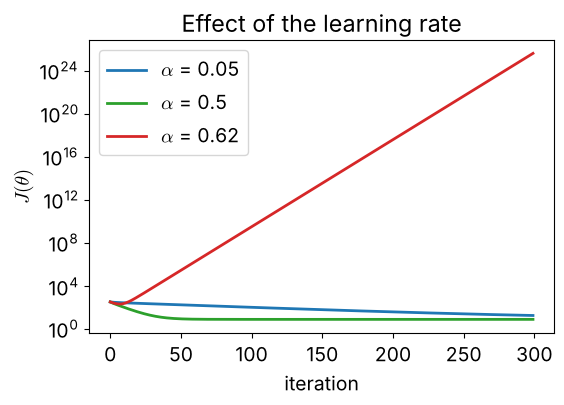

In [6]:
def run(lr, steps=300):
    mdl = nn.Linear(1, 1)
    with torch.no_grad():
        mdl.bias.fill_(220.0); mdl.weight.fill_(-40.0)
    o = torch.optim.SGD(mdl.parameters(), lr=lr)
    hist = []
    for _ in range(steps):
        l = loss_fn(mdl(x), y)
        hist.append(l.item())
        o.zero_grad(); l.backward(); o.step()
    return hist

plt.figure(figsize=(6, 3.8))
for lr, c in [(0.05, 'tab:blue'), (0.5, 'tab:green'), (0.62, 'tab:red')]:
    plt.plot(run(lr), color=c, lw=2, label=f'$\\alpha$ = {lr}')
plt.yscale('log'); plt.xlabel('iteration'); plt.ylabel('$J(\\theta)$'); plt.legend(); plt.title('Effect of the learning rate')
plt.show()

## 6. Same recipe, new hypothesis: logistic regression is one neuron
Tumor size (cm) and label (0 = benign, 1 = malignant). Only **two lines** change with respect to linear regression:
the output goes through a sigmoid, and the cost becomes the cross-entropy (log-loss) `nn.BCELoss()`.

In [7]:
size_cm = torch.tensor([1.0, 1.5, 1.9, 2.3, 2.8, 3.4, 3.0, 3.9, 4.3, 4.8, 5.2, 5.9]).unsqueeze(1)
label = torch.tensor([0., 0., 0., 0., 0., 0., 1., 1., 1., 1., 1., 1.]).unsqueeze(1)

neuron = nn.Linear(1, 1)                       # z = w x + b
with torch.no_grad():
    neuron.weight.fill_(0.0); neuron.bias.fill_(0.0)
bce = nn.BCELoss()                             # J(theta) = -mean[y log h + (1-y) log(1-h)]
opt = torch.optim.SGD(neuron.parameters(), lr=0.5)

lpath, llosses = [], []
for step in range(3000):
    p = torch.sigmoid(neuron(size_cm))         # forward pass: h = g(z), a probability
    loss = bce(p, label)
    lpath.append((neuron.bias.item(), neuron.weight.item())); llosses.append(loss.item())
    opt.zero_grad(); loss.backward(); opt.step()
lpath = np.array(lpath)
b, w = neuron.bias.item(), neuron.weight.item()
print(f'b = {b:.2f}, w = {w:.2f}, decision boundary at size = {-b / w:.2f} cm, final J = {llosses[-1]:.3f}')

b = -10.28, w = 3.15, decision boundary at size = 3.26 cm, final J = 0.214


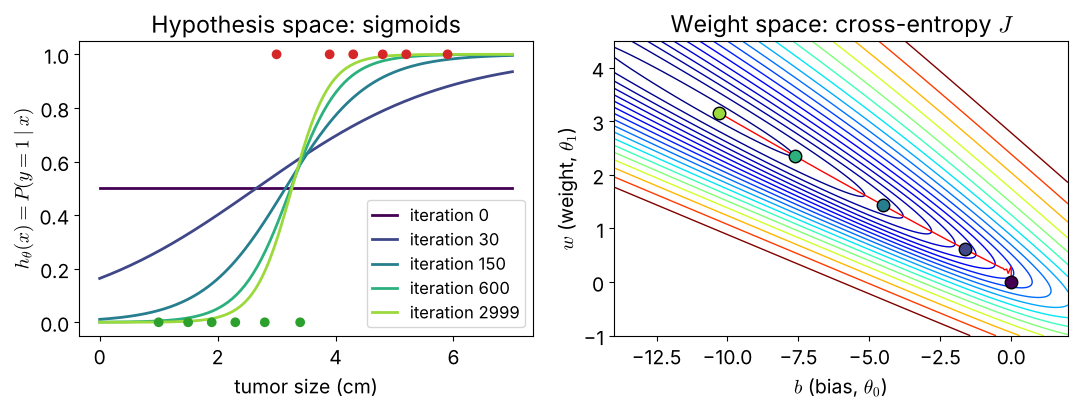

In [8]:
def bce_grid(B, W):
    X = size_cm.numpy().ravel(); Y = label.numpy().ravel()
    Z = B[..., None] + W[..., None] * X
    P = 1 / (1 + np.exp(-Z))
    P = np.clip(P, 1e-9, 1 - 1e-9)
    return -(Y * np.log(P) + (1 - Y) * np.log(1 - P)).mean(axis=-1)

B, W = np.meshgrid(np.linspace(-14, 2, 300), np.linspace(-1, 4.5, 300))
JL = bce_grid(B, W)
showl = [0, 30, 150, 600, 2999]
cols = plt.cm.viridis(np.linspace(0, 0.85, len(showl)))

fig, ax = plt.subplots(1, 2, figsize=(11, 4.3))
s = np.linspace(0, 7, 200)
ax[0].scatter(size_cm, label, c=['tab:green' if v == 0 else 'tab:red' for v in label.ravel()], zorder=3)
for c, k in zip(cols, showl):
    ax[0].plot(s, 1 / (1 + np.exp(-(lpath[k, 0] + lpath[k, 1] * s))), color=c, lw=2, label=f'iteration {k}')
ax[0].set(xlabel='tumor size (cm)', ylabel='$h_\\theta(x)=P(y=1\\mid x)$', title='Hypothesis space: sigmoids')
ax[0].legend(fontsize=12, loc='lower right', labelspacing=0.25, borderpad=0.3, handlelength=1.5)
ax[1].contour(B, W, JL, levels=np.geomspace(JL.min() + 0.01, 3, 18), cmap='jet', linewidths=1)
ax[1].plot(lpath[:, 0], lpath[:, 1], 'r-', lw=1)
for c, k in zip(cols, showl):
    ax[1].plot(*lpath[k], 'o', color=c, ms=9, mec='k')
ax[1].set(xlabel='$b$ (bias, $\\theta_0$)', ylabel='$w$ (weight, $\\theta_1$)', title='Weight space: cross-entropy $J$')
plt.tight_layout()
if SAVE_FIGS:
    plt.savefig(f'{FIG_DIR}/demo_neuron_two_spaces.png', dpi=200)
plt.show()

## 7. Try it yourself
1. Start linear regression from a different line (change `fill_`). Does it end at the same weights? Why? (Hint: the cost is convex.)
2. In section 5, find the largest learning rate that still converges.
3. Replace `nn.BCELoss()` with `nn.MSELoss()` for the neuron. Does training still work? What happens to the shape of $J$ in weight space?
4. Count the weights: how many numbers does each model learn?